# Adversarial Search: Solving Tic-Tac-Toe with Minimax Search and Alpha-Beta Pruning

## Introduction 

Multiplayer games can be implemented as:
1. Nondeterministic actions: The opponent is seen as part of an environment with nondeterministic actions. Non-determinism is the result of the unknown opponent's moves. 
2. __Optimal Decisions:__ Minimax search (search complete game tree) and alpha-beta pruning.
3. Heuristic Alpha-Beta Tree Search: Cut off tree search and use heuristic to estimate state value. 
4. Monte Carlo Tree search: Simulate playouts to estimate state value. 

Here we will implement search for Tic-Tac-Toe (see [rules](https://en.wikipedia.org/wiki/Tic-tac-toe)). The game is a __zero-sum game__: Win by x results in +1, win by o in -1 and a tie has a value of 0. Max plays x and tries to maximize the outcome while Min plays o and tries to minimize the outcome.   

We will implement
* __minimax search,__
* __minimax search with alpha-beta pruning,__ and
* __move ordering__. 

The search time (number if nodes explored) could be further improved by 
* __heuristic alpha-beta tree search__ (cut off search and use heuristic evaluation function to approximate utility), 
* __forward pruning__ (prune moves that appear poor), and
* __table lookups__ (for openings and end game).

The algorithms search the game tree and we could return a conditional plan (or partial plan if cut offs are used), but the implementation here only identifies and returns the optimal next move.

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

In [3]:
# Hàm phụ: cho tác tử đấu random_player 100 ván khi đi trước (x) và 100 ván khi đi sau (o), đo thời gian mỗi nước
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tictactoe import other
np.random.seed(0)

def danh_gia(agent, ten, N = 100):
    dong = []
    for vai in 'xo':
        t = []
        def dem(board, player = 'x'):
            s = time.perf_counter(); a = agent(board, player); t.append(time.perf_counter() - s); return a
        r = play(dem, random_player, N) if vai == 'x' else play(random_player, dem, N)
        dong.append([ten, 'đi trước' if vai == 'x' else 'đi sau', r[vai], r['d'], r[other(vai)], round(1000 * np.mean(t), 1)])
    return pd.DataFrame(dong, columns = ['Tác tử', 'Vai', 'Thắng', 'Hòa', 'Thua', 'ms/nước'])

def ve(bang, tieu_de):
    nhan = bang['Tác tử'] + ' (' + bang['Vai'] + ')'
    ax = bang[['Thắng', 'Hòa', 'Thua']].set_index(nhan).plot.barh(stacked = True, color = ['#2a78d6', '#c3c2b7', '#eb6834'], figsize = (8, 0.45 * len(bang) + 1.3))
    ax.set_xlabel('số ván'); ax.set_ylabel(''); ax.set_title(tieu_de); ax.invert_yaxis()
    ax.legend(ncol = 3, loc = 'upper center', bbox_to_anchor = (0.5, -0.2))
    plt.show()

In [ ]:
# Bốn trạng thái kiểm thử (đến lượt x đi)
def ban(x = (), o = ()):
    b = empty_board()
    for i in x: b[i] = 'x'
    for i in o: b[i] = 'o'
    return b

tests = {'A: x sắp thắng': ban((0, 4), (1, 3)), 'B: x phải đi ô 7': ban((0, 2), (1, 4)),
         'C: bất lợi': ban((2,), (0, 8)), 'D: bàn rỗng': ban()}

# Recursive DFS algorithm for Minimax Search

See AIMA page 150. 

Note that the minimax search algorithm is very similar to AND-OR search where max does OR and min is represented by AND nodes.

In [5]:
import math

# global variables
DEBUG = 1 # 1 ... count nodes, 2 ... debug each node
COUNT = 0

def minimax_search(board, player = 'x'):
    """start the search."""
    global DEBUG, COUNT
    COUNT = 0
    
    value, move = max_value(board, player)
    
    if DEBUG >= 1: print(f"Number of nodes searched: {COUNT}") 
 
    return { "move": move, "value": value}

def max_value(state, player):
    """player's best move."""
    global DEBUG, COUNT
    COUNT += 1
    
    # return utility of state if it is a terminal state
    v = utility(state, player)
    if DEBUG >= 2: print("max in: " + str(state) + str([v]) ) 
    if v is not None: return v, None
        
    v, move = -math.inf, None

    # check all possible actions in the state, return move with the largest value
    for a in actions(state):
        v2, a2 = min_value(result(state, player, a), player)
        if v2 > v:
            v, move = v2, a
    
    if DEBUG >= 2: print("max out: " + str(state) + str([v, move]) ) 
    return v, move

def min_value(state, player):
    """opponent's best response."""
    global DEBUG, COUNT
    COUNT += 1
    
    # return utility of state if it is a terminal state
    v = utility(state, player)
    if DEBUG >= 2: print("min in: " + str(state) + str([v]) ) 
    if v is not None: return v, None
    
    v, move = +math.inf, None

    # check all possible actions in the state, return move with the smallest value
    for a in actions(state):
        v2, a2 = max_value(result(state, other(player), a), player)
        if v2 < v:
            v, move = v2, a
    
    if DEBUG >= 2: print("min out: " + str(state) + str([v, move]) ) 
    return v, move

## Some Tests

### x is about to win (choose 8)

Board:


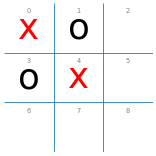


Number of nodes searched: 190


{'move': 2, 'value': 1}

CPU times: total: 0 ns
Wall time: 11.6 ms


In [6]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
%time display(minimax_search(board))

**Note:** DFS does not pick the the shortest path to a win! Discounting the utility can help.

### x can draw if it chooses 7

Board:


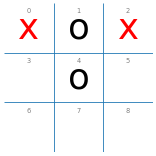


Number of nodes searched: 206


{'move': 7, 'value': 0}

CPU times: total: 0 ns
Wall time: 12.7 ms


In [7]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
board[4] = 'o'

print("Board:")
show_board(board)

print()
%time display(minimax_search(board))

### A bad situation


Board:


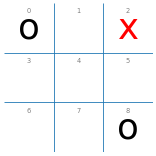


Number of nodes searched: 941


{'move': 1, 'value': -1}

CPU times: total: 31.2 ms
Wall time: 40.2 ms


In [8]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)

print()
%time display(minimax_search(board))

### Empty board

Board:


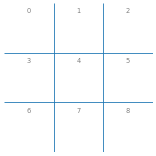


Number of nodes searched: 549946


{'move': 0, 'value': 0}

CPU times: total: 17.2 s
Wall time: 17.8 s


In [9]:
board = empty_board() 

print("Board:")
show_board(board)


print()
%time display(minimax_search(board))

__Note:__ Starting with an empty board searched the complete game tree and takes a while. The number of nodes above is the actual size of the complete game tree. A table with know 'openings' (e.g., place x in a corner, o chooses the center, etc.) would be helpful to speed things up.

# Recursive DFS algorithm for Minimax Search with Alpha-Beta Pruning

See AIMA page 154. 

Adds alpha-beta pruning to minimax search. Alpha and beta are used to maintain bounds on the minimax value of a node in the form `[alpha, beta]`. alpha means that the value is at least that high and beta means that the actual value is at most that high. Subtrees below a node that are worse than the currently known bound do not need to be further explored and can be pruned. Max uses alpha and Min uses beta for pruning.

The implementation is for player 'x' returns a the optimal next move.

In [10]:
# global variables
DEBUG = 1 # 1 ... count nodes, 2 ... debug each node
COUNT = 0

def alpha_beta_search(board, player = 'x'):
    """start the search."""
    global DEBUG, COUNT
    COUNT = 0
    
    value, move = max_value_ab(board, player, -math.inf, +math.inf)
    
    if DEBUG >= 1: print(f"Number of nodes searched: {COUNT}") 
    
    return { "move": move, "value": value }

def max_value_ab(state, player, alpha, beta):
    """player's best move."""
    global DEBUG, COUNT
    COUNT += 1
       
    # return utility of state is a terminal state
    v = utility(state, player)
    if DEBUG >= 2: print(f"max: {state} [alpha,beta]=[{alpha},{beta}] v={v}")
    if v is not None: 
        if DEBUG >= 2: print(f"     found terminal state. backtracking.")
        return v, None
        
    v, move = -math.inf, None

    # check all possible actions in the state, update alpha and return move with the largest value
    for a in actions(state):
        v2, a2 = min_value_ab(result(state, player, a), player, alpha, beta)
        if DEBUG >= 2: print(f"max: {state} (backtracked) [alpha,beta]=[{alpha},{beta}] v={v2}")
        
        if v2 > v:
            v, move = v2, a
            alpha = max(alpha, v)
        if v >= beta:
            if DEBUG >= 2: print(f"     v>=beta ({v}>={beta}): pruning remaining subtree (actions). backtracking.")
            return v, move
    
    return v, move

def min_value_ab(state, player, alpha, beta):
    """opponent's best response."""
    global DEBUG, COUNT
    COUNT += 1
    
    # return utility of state is a terminal state
    v = utility(state, player)
    if DEBUG >= 2: print(f"min: {state} [alpha,beta]=[{alpha},{beta}] v={v}")
    if v is not None: 
        if DEBUG >= 2: print(f"     found terminal state. backtacking.")
        return v, None
    
    v, move = +math.inf, None

    # check all possible actions in the state, update beta and return move with the smallest value
    for a in actions(state):
        v2, a2 = max_value_ab(result(state, other(player), a), player, alpha, beta)
        if DEBUG >= 2: print(f"min: {state} (backtracked) [alpha,beta]=[{alpha},{beta}] v={v2}")
        
        if v2 < v:
            v, move = v2, a
            beta = min(beta, v)
        if v <= alpha: 
            if DEBUG >= 2: print(f"     v<=alpha ({v}<={alpha}): pruning remaining subtree (actions). backtracking.")
            return v, move
    
    return v, move

## Some Tests

### x is about to win (play 8)

Board:


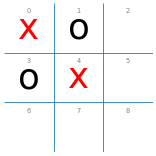


max: ['x', 'o', ' ', 'o', 'x', ' ', ' ', ' ', ' '] [alpha,beta]=[-inf,inf] v=None
min: ['x', 'o', 'x', 'o', 'x', ' ', ' ', ' ', ' '] [alpha,beta]=[-inf,inf] v=None
max: ['x', 'o', 'x', 'o', 'x', 'o', ' ', ' ', ' '] [alpha,beta]=[-inf,inf] v=None
min: ['x', 'o', 'x', 'o', 'x', 'o', 'x', ' ', ' '] [alpha,beta]=[-inf,inf] v=1
     found terminal state. backtacking.
max: ['x', 'o', 'x', 'o', 'x', 'o', ' ', ' ', ' '] (backtracked) [alpha,beta]=[-inf,inf] v=1
min: ['x', 'o', 'x', 'o', 'x', 'o', ' ', 'x', ' '] [alpha,beta]=[1,inf] v=None
max: ['x', 'o', 'x', 'o', 'x', 'o', 'o', 'x', ' '] [alpha,beta]=[1,inf] v=None
min: ['x', 'o', 'x', 'o', 'x', 'o', 'o', 'x', 'x'] [alpha,beta]=[1,inf] v=1
     found terminal state. backtacking.
max: ['x', 'o', 'x', 'o', 'x', 'o', 'o', 'x', ' '] (backtracked) [alpha,beta]=[1,inf] v=1
min: ['x', 'o', 'x', 'o', 'x', 'o', ' ', 'x', ' '] (backtracked) [alpha,beta]=[1,inf] v=1
     v<=alpha (1<=1): pruning remaining subtree (actions). backtracking.
max: ['x', 'o'

{'move': 2, 'value': 1}

CPU times: total: 15.6 ms
Wall time: 7.76 ms


In [11]:
DEBUG = 2 # show more debugging info

board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board))

The code does not pick the the shortest path to a win! Discounting could help.

### x can draw if it chooses 7

Board:


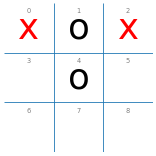


Number of nodes searched: 101


{'move': 7, 'value': 0}

CPU times: total: 15.6 ms
Wall time: 7.17 ms


In [12]:
DEBUG = 1

board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
board[4] = 'o'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board))

### o is about to win no matter what x does


Board:


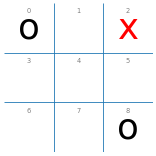


Number of nodes searched: 238


{'move': 1, 'value': -1}

CPU times: total: 15.6 ms
Wall time: 13.8 ms


In [13]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board))

### Empty board: Only a draw an be guaranteed

Board:


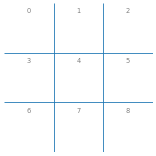


Number of nodes searched: 18297


{'move': 0, 'value': 0}

CPU times: total: 750 ms
Wall time: 760 ms


In [14]:
board = empty_board() 

print("Board:")
show_board(board)


print()
%time display(alpha_beta_search(board))

**Note:** Alpha-Beta search expands fewer nodes and is **much faster** than minimax search. 

## Move ordering

Smart move reordering can make alpha-beta pruning more effective. I think the center `[4]` and corners `[0, 2, 6, 8]` are good. I implement move reordering in the `actions()`.

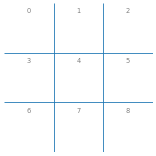

[4, 8, 6, 2, 0, 7, 5, 3, 1]

In [15]:
import numpy as np

def actions(board):
    """return possible actions as a vector ot indices"""
    actions = np.where(np.array(board) == ' ')[0].tolist()

    priority = [1,0,1,
                0,2,0,
                1,0,1]
    priority = [priority[i] for i in actions]
    
    actions =[a for _,a in sorted(zip(priority,actions), reverse=True)]
    
    return actions

board = empty_board()   
show_board(board)
actions(board)

### Empty board: Only a draw an be guaranteed

Board:


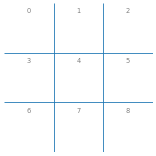


Number of nodes searched: 7275


{'move': 4, 'value': 0}

CPU times: total: 266 ms
Wall time: 268 ms


In [16]:
board = empty_board() 

print("Board:")
show_board(board)


print()
%time display(alpha_beta_search(board))

__Note:__ Compare to the number of nodes searched without move reordering (right above).

## Experiments


### Minimax with Alpha-Beta Pruning vs. Random

In [17]:
DEBUG = 0

def alpha_beta_player(board, player = 'x'):
    return alpha_beta_search(board, player)["move"]

print("alpha-beta vs. random:")
%time display(play(alpha_beta_player, random_player))

print()
print("random vs. alpha-beta")
%time display(play(random_player, alpha_beta_player))

alpha-beta vs. random:


{'x': 98, 'o': 0, 'd': 2}

CPU times: total: 38.8 s
Wall time: 40.5 s

random vs. alpha-beta


{'x': 0, 'o': 81, 'd': 19}

CPU times: total: 11.6 s
Wall time: 12.3 s


**Note on runtime:** Compared to AND-OR Search, Minimax search is slower, because AND-OR Search terminates once it finds the first subtree that has only goal nodes, buy Minimax search traverses the whole tree (minus what is pruned if alpha-beta pruning is used). 

Also, I was lazy and recreate the search tree every time the agent is asked for a move. The agent could create the tree with the Minimax values once and then use it to decide on actions. A problem could be that the tree may be too large to store. 

,Trạng thái,Thuật toán,Nước đi,Giá trị,Số nút,ms
0,A: x sắp thắng,minimax_search,2,1,190,10.5
1,A: x sắp thắng,alpha_beta_search,2,1,61,3.3
2,B: x phải đi ô 7,minimax_search,7,0,206,8.0
3,B: x phải đi ô 7,alpha_beta_search,7,0,101,3.8
4,C: bất lợi,minimax_search,1,-1,941,39.8
5,C: bất lợi,alpha_beta_search,1,-1,238,11.2
6,D: bàn rỗng,minimax_search,0,0,549946,28729.5
7,D: bàn rỗng,alpha_beta_search,0,0,18297,1272.4


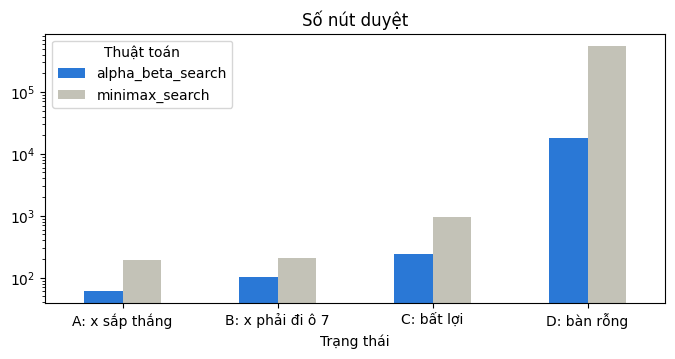

In [18]:
#  Minimax và Alpha-Beta trên cùng các trạng thái (thứ tự nước đi gốc: theo chỉ số ô)
actions_ordered = actions                       # bản có move ordering đã định nghĩa ở trên
def actions_plain(board):
    return np.where(np.array(board) == ' ')[0].tolist()

DEBUG = 0
actions = actions_plain
dong = []
for ten, b in tests.items():
    for ham in (minimax_search, alpha_beta_search):
        t = time.perf_counter(); r = ham(b)
        dong.append([ten, ham.__name__, r['move'], r['value'], COUNT, round(1000 * (time.perf_counter() - t), 1)])
bang = pd.DataFrame(dong, columns = ['Trạng thái', 'Thuật toán', 'Nước đi', 'Giá trị', 'Số nút', 'ms'])
display(bang)
bang.pivot(index = 'Trạng thái', columns = 'Thuật toán', values = 'Số nút').plot.bar(logy = True, color = ['#2a78d6', '#c3c2b7'], rot = 0, figsize = (8, 3.5), title = 'Số nút duyệt')
plt.show()

**Nhận xét:** Minimax và Alpha-Beta cho cùng nước đi và cùng giá trị ở cả bốn trạng thái, nhưng Alpha-Beta duyệt ít nút hơn nhiều (bàn rỗng: 18.297 so với 549.946 nút, thời gian khoảng 0,7 giây so với 19 giây). Vì vậy cắt tỉa không làm thay đổi quyết định tối ưu. Ở trạng thái A cả hai chọn ô 2 chứ không phải ô 8 vì DFS chỉ so sánh giá trị (+1) và giữ nước đầu tiên đạt giá trị đó.

,Trạng thái,Thứ tự nước đi,Số nút
0,A: x sắp thắng,theo chỉ số,61
1,A: x sắp thắng,có ordering,42
2,B: x phải đi ô 7,theo chỉ số,101
3,B: x phải đi ô 7,có ordering,106
4,C: bất lợi,theo chỉ số,238
5,C: bất lợi,có ordering,36
6,D: bàn rỗng,theo chỉ số,18297
7,D: bàn rỗng,có ordering,7275


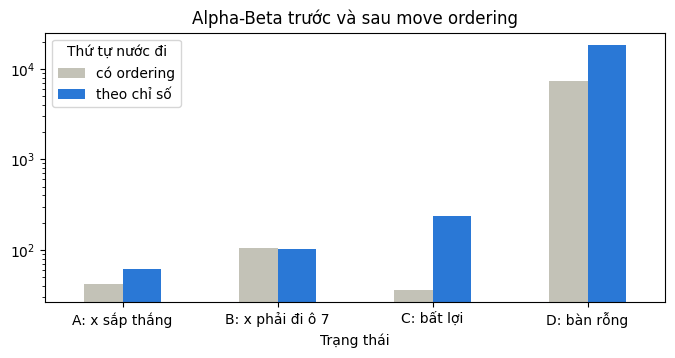

In [19]:
# Move ordering: số nút của Alpha-Beta khi thử nước đi theo chỉ số ô và khi ưu tiên giữa > góc > cạnh
dong = []
for ten, b in tests.items():
    for cach, ham in (('theo chỉ số', actions_plain), ('có ordering', actions_ordered)):
        actions = ham; alpha_beta_search(b); dong.append([ten, cach, COUNT])
actions = actions_ordered
bang = pd.DataFrame(dong, columns = ['Trạng thái', 'Thứ tự nước đi', 'Số nút'])
display(bang)
bang.pivot(index = 'Trạng thái', columns = 'Thứ tự nước đi', values = 'Số nút').plot.bar(logy = True, color = ['#c3c2b7', '#2a78d6'], rot = 0, figsize = (8, 3.5), title = 'Alpha-Beta trước và sau move ordering')
plt.show()

**Nhận xét:** Ưu tiên ô giữa, rồi góc, rồi cạnh làm giảm số nút ở bàn rỗng (18.297 → 7.275), ở A (61 → 42) và ở C (238 → 36), nhưng ở B lại tăng nhẹ (101 → 106). Thứ tự tốt giúp cắt tỉa hiệu quả vì nước mạnh được xét trước làm `alpha`/`beta` đạt giá trị tốt sớm, nên nhiều nhánh còn lại bị cắt; nhưng đây chỉ là heuristic nên không luôn giảm.

,Tác tử,Vai,Thắng,Hòa,Thua,ms/nước
0,Alpha-Beta,đi trước,99,1,0,147.9
1,Alpha-Beta,đi sau,89,11,0,42.6


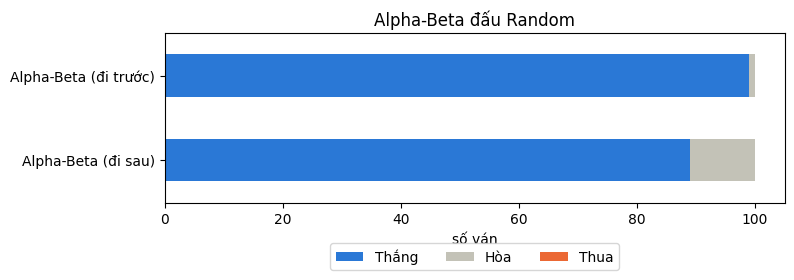

In [20]:
# Alpha-Beta đấu Random
bang = danh_gia(alpha_beta_player, 'Alpha-Beta')
display(bang)
ve(bang, 'Alpha-Beta đấu Random')

**Nhận xét:** Alpha-Beta không thua ván nào: đi trước thắng 99, hòa 1; đi sau thắng 89, hòa 11. Thời gian mỗi nước khi đi trước (≈ 70 ms) cao hơn khi đi sau (≈ 20 ms) vì nước đầu tiên phải tìm kiếm trên bàn gần rỗng.